In [1]:
cd /Users/cl1704/PycharmProjects/embedding_dimension/BWM

/Users/cl1704/PycharmProjects/embedding_dimension/BWM


In [2]:
import pandas as pd
import skdim
import scipy

from scipy.stats import gaussian_kde
from matplotlib import gridspec
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib
import numpy as np
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
import torch
import random
import string
import os
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset, TensorDataset
from scipy.ndimage import gaussian_filter1d
from sklearn.decomposition import PCA
from iblatlas.regions import BrainRegions
br = BrainRegions()
import umap
from iblatlas.regions import BrainRegions
br = BrainRegions()
from bwm_functions import *
import os
import pandas as pd
import seaborn as sns
from matplotlib import gridspec
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE
import matplotlib
import torch
import numpy as np
plt.rcParams["axes.grid"] = False
matplotlib.rcParams['axes.linewidth'] = .5

In [3]:
directory_path = 'Data2'
all_items = os.listdir(directory_path)
print(len(all_items))
# Filter the list to include only folders (directories)
eids = [item for item in all_items if os.path.isdir(os.path.join(directory_path, item))]

460


In [4]:
eid = eids[202]

In [5]:
#########################################################################
###################### Generate response matrix for eid #################
#########################################################################

full_path_to_random_folder = os.path.join(directory_path, eid)
print(f"Randomly selected eid: {full_path_to_random_folder}")

# for _ in range(1):

dim = 5
sample_size = 50
sigma = 5
n_steps = 100
threshold = .01
min_trials_per_condition = 50
conditions = ['choice']
event = "stimOn_times"
clusters = pd.read_pickle(full_path_to_random_folder + '/clusters.pkl')

clusters['cosmos'] = br.id2acronym(clusters['atlas_id'], mapping="Cosmos")

spikes = pd.read_pickle(full_path_to_random_folder + '/spikes.pkl')
trials = pd.read_pickle(full_path_to_random_folder + '/trials.pkl')

counts_series = clusters.groupby('cosmos').size()
print(counts_series)

# shape n_pseudo x n_conditions x time x n
response_matrix_train, condition_matrix_train = get_aligned_response_matrix(
spikes, clusters, trials, event, conditions,
stride=.005,
step=.005,
n_steps=n_steps,
sigma=sigma,
threshold=threshold,
min_trials_per_condition=min_trials_per_condition,regions =  counts_series.index.values)
    #
    # [item for item in counts_series.index.values if item not in ['root','void']])
# min_trials_per_condition=min_trials_per_condition,regions = ["Isocortex"])

# Restrict to active units
restriction = np.logical_and(np.std(response_matrix_train, axis=(0, 1, 2)) > .01,
                         np.std(response_matrix_train, axis=(0, 1, 2)) > .01)
response_matrix_train = response_matrix_train[
:, :, :, restriction]

z = np.mean(response_matrix_train, axis = 0)
responses = (response_matrix_train - np.mean(z, axis=(0, 1),
                                                     keepdims=True)) / np.std(z,
                                                                              axis=(0, 1),
                                                                              keepdims=True)
#data_snr =np.mean(np.std(responses, axis=0), axis=(0, 1))
#data =np.log(np.mean(response_matrix_train, axis=(0, 1,2)))
responses = np.mean(responses, axis=0)
response_matrix = responses.reshape(-1, responses.shape[2])
print(response_matrix.shape)

Randomly selected eid: Data2/746d1902-fa59-4cab-b0aa-013be36060d5
cosmos
CB       144
HB      1138
HPF      195
HY       137
TH       796
root     111
dtype: int64
(200, 2510)


In [6]:
data_snr = []
for neuron in range(responses.shape[2]):
    means = []
    for t in range(99):
        h = (responses[:, t + 1, neuron] - responses[:, t, neuron]) / (responses[:, t, neuron] + 10)
        means.append(np.abs(np.mean(h)))
    data_snr.append(np.mean(means))


In [7]:
X_tensor = torch.FloatTensor(response_matrix.T)
X_scaled = X_tensor/torch.linalg.norm(X_tensor, dim=1, keepdim=True)
X_scaled = PCA(n_components = 20).fit_transform(X_scaled)

In [8]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset, Subset
from sklearn.model_selection import KFold
from tqdm.auto import tqdm
import os
import sys

# Add project root to path to import the new model
sys.path.append(os.path.abspath('../../'))
from BWM.models.isometric_autoencoder import SklearnIsometricAutoencoder




In [35]:
# Retrain with best params for 1000 epochs
isoAE = SklearnIsometricAutoencoder(
    latent_dim=2,
    hidden_dim=256,
    depth=2,
    epochs=500,
    batch_size=128,
    lambda_iso = 10.0
)
isoAE.fit(X_scaled)


Training:   0%|          | 0/500 [00:00<?, ?it/s]

Train R2:   0%|          | 0/100 [00:00<?, ?it/s]

Test  R2:   0%|          | 0/100 [00:00<?, ?it/s]

KeyboardInterrupt: 

In [13]:
isoAE.lambda_iso

1.0

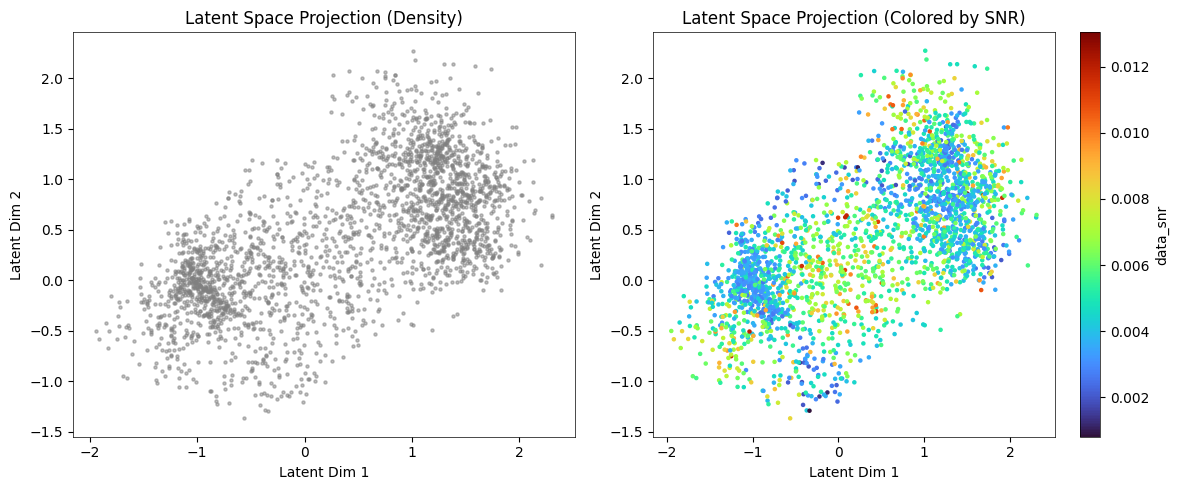

In [36]:
def plot_latent_space_wrapped(model_wrapper, data, snr_values):
    z = model_wrapper.transform(data)
    
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    
    # Plot 1: Density (Gray with alpha=0.5)
    axes[0].scatter(z[:, 0], z[:, 1], color='gray', alpha=0.5, s=5)
    axes[0].set_title("Latent Space Projection (Density)")
    axes[0].set_xlabel("Latent Dim 1")
    axes[0].set_ylabel("Latent Dim 2")
    
    # Plot 2: Colored by data_snr
    sc = axes[1].scatter(z[:, 0], z[:, 1], c=snr_values, cmap='turbo', s=5)
    plt.colorbar(sc, ax=axes[1], label='data_snr')
    axes[1].set_title("Latent Space Projection (Colored by SNR)")
    axes[1].set_xlabel("Latent Dim 1")
    axes[1].set_ylabel("Latent Dim 2")
    
    plt.tight_layout()
    plt.show()

# Visualize the result
plot_latent_space_wrapped(isoAE, X_scaled, data_snr)


In [11]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons

# --- 1. Data Normalization Utility ---
class Standardizer:
    def __init__(self, data):
        self.mean = data.mean(dim=0)
        self.std = data.std(dim=0)

    def transform(self, data):
        return (data - self.mean) / (self.std + 1e-6)

    def inverse_transform(self, data):
        return (data * (self.std + 1e-6)) + self.mean

# --- 2. Model Components (RealNVP) ---

In [25]:
# Grid Search over hidden_dim, depth, and lambda_iso
import itertools

# Define the grid of parameters
hidden_dims = [32,64,128,256]
depths = [1,2, 4,8,10,16]
lambda_isos = [1.0,10, 20.0]

results = []

# Total combinations for the progress bar
total_combinations = len(hidden_dims) * len(depths) * len(lambda_isos)

print(f"Starting grid search with {total_combinations} combinations...")

for h_dim, d, l_iso in itertools.product(hidden_dims, depths, lambda_isos):
    print(f"\nEvaluating: hidden_dim={h_dim}, depth={d}, lambda_iso={l_iso}")
    
    # Initialize the model with current parameters
    model = SklearnIsometricAutoencoder(
        latent_dim=2,
        hidden_dim=h_dim,
        depth=d,
        epochs=50, # Reduced epochs for faster grid search
        batch_size=128,
        lambda_iso=l_iso,
        verbose=False # Set verbose to False to avoid too much output
    )
    
    # Calculate mean R2 across folds using cv_score
    # n_folds=3 for a balance between speed and reliability
    mean_test_r2, mean_train_r2 = model.cv_score(X_scaled, n_folds=3, return_train_score=True)
    
    results.append({
        'hidden_dim': h_dim,
        'depth': d,
        'lambda_iso': l_iso,
        'test_r2': mean_test_r2,
        'train_r2': mean_train_r2
    })
    
    print(f"Mean Test R2: {mean_test_r2:.4f}, Mean Train R2: {mean_train_r2:.4f}")

# Convert results to DataFrame for easy viewing
df_results = pd.DataFrame(results)
print("\nGrid Search Results:")
print(df_results.sort_values(by='test_r2', ascending=False))


Starting grid search with 72 combinations...

Evaluating: hidden_dim=32, depth=1, lambda_iso=1.0
Mean Test R2: 0.5582, Mean Train R2: 0.5647

Evaluating: hidden_dim=32, depth=1, lambda_iso=10
Mean Test R2: 0.4506, Mean Train R2: 0.4541

Evaluating: hidden_dim=32, depth=1, lambda_iso=20.0
Mean Test R2: 0.3738, Mean Train R2: 0.3724

Evaluating: hidden_dim=32, depth=2, lambda_iso=1.0
Mean Test R2: 0.5605, Mean Train R2: 0.5694

Evaluating: hidden_dim=32, depth=2, lambda_iso=10
Mean Test R2: 0.4040, Mean Train R2: 0.4056

Evaluating: hidden_dim=32, depth=2, lambda_iso=20.0
Mean Test R2: 0.3606, Mean Train R2: 0.3649

Evaluating: hidden_dim=32, depth=4, lambda_iso=1.0
Mean Test R2: 0.5771, Mean Train R2: 0.5803

Evaluating: hidden_dim=32, depth=4, lambda_iso=10
Mean Test R2: 0.3792, Mean Train R2: 0.3789

Evaluating: hidden_dim=32, depth=4, lambda_iso=20.0
Mean Test R2: 0.3103, Mean Train R2: 0.3120

Evaluating: hidden_dim=32, depth=8, lambda_iso=1.0
Mean Test R2: 0.4277, Mean Train R2: 0.

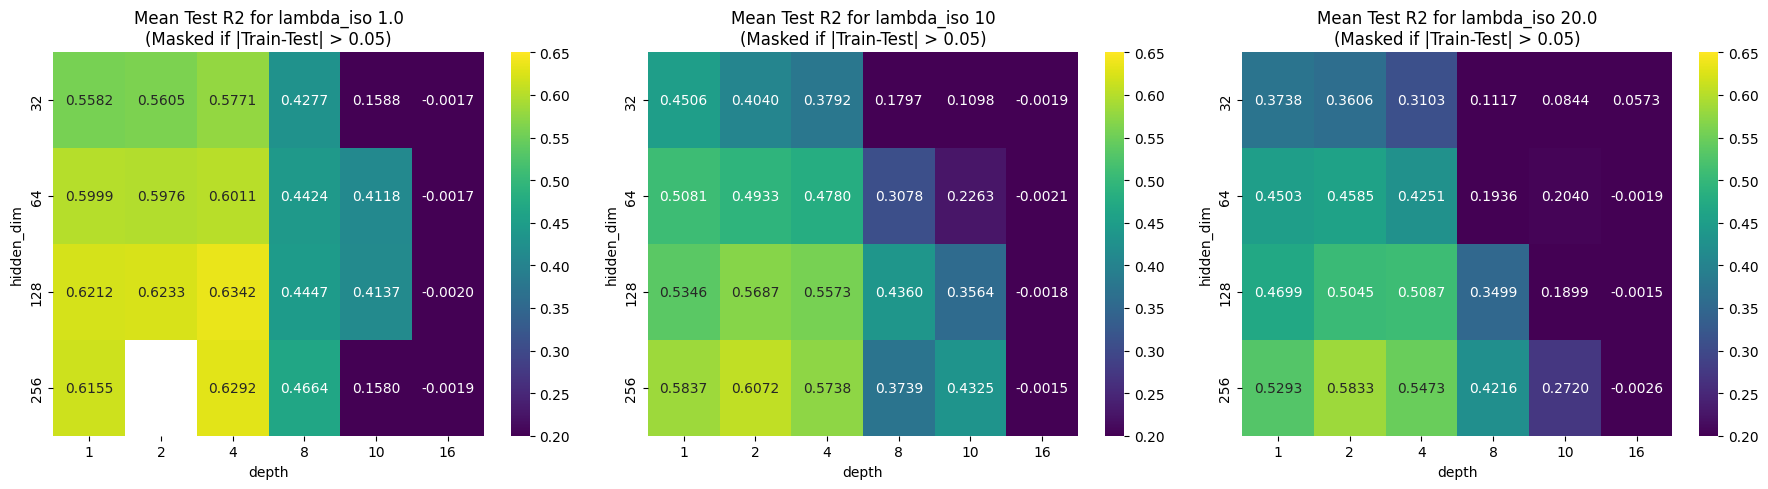

In [28]:
# Visualize Grid Search Results
import seaborn as sns

# Create heatmaps for different lambda_iso side-by-side
fig, axes = plt.subplots(1, len(lambda_isos), figsize=(6 * len(lambda_isos), 5), squeeze=False)
for i, l in enumerate(lambda_isos):
    subset = df_results[df_results['lambda_iso'] == l]
    pivot_test = subset.pivot(index='hidden_dim', columns='depth', values='test_r2')
    pivot_train = subset.pivot(index='hidden_dim', columns='depth', values='train_r2')
    
    # Create a mask for differences > 0.05
    mask = np.abs(pivot_test - pivot_train) > 0.02
    
    sns.heatmap(pivot_test, annot=True, fmt=".4f", cmap='viridis', ax=axes[0, i], vmin=0.2, vmax=.65, mask=mask)
    axes[0, i].set_title(f"Mean Test R2 for lambda_iso {l}\n(Masked if |Train-Test| > 0.05)")
plt.tight_layout()
plt.show()


In [ ]:
# --- 2. Model Components (RealNVP) ---
class CouplingLayer(nn.Module):
    def __init__(self, input_dim, hidden_dim, mask):
        super().__init__()
        self.mask = nn.Parameter(mask, requires_grad=False)
        self.nn = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, input_dim * 2)
        )

    def forward(self, x, reverse=False):
        x_masked = x * self.mask
        out = self.nn(x_masked)
        s, t = out.chunk(2, dim=1)
        s = torch.tanh(s)

        if not reverse:
            z = x_masked + (1 - self.mask) * (x - t) * torch.exp(-s)
            log_det_jac = torch.sum((1 - self.mask) * (-s), dim=1)
            return z, log_det_jac
        else:
            x = x_masked + (1 - self.mask) * (x * torch.exp(s) + t)
            return x

class RealNVP(nn.Module):
    def __init__(self, num_layers=6, hidden_dim=64):
        super().__init__()
        self.layers = nn.ModuleList()
        masks = [torch.tensor([1.0, 0.0]), torch.tensor([0.0, 1.0])] * (num_layers // 2)
        for mask in masks:
            self.layers.append(CouplingLayer(2, hidden_dim, mask))

    def log_prob(self, x):
        log_det_sum = 0
        z = x
        for layer in self.layers:
            z, log_det = layer(z)
            log_det_sum += log_det
        log_p_z = -0.5 * (torch.log(torch.tensor(2 * np.pi)) + z**2).sum(dim=1)
        return log_p_z + log_det_sum

    # --- ADD THIS METHOD ---
    def sample(self, num_samples):
        # 1. Sample from the base distribution (Standard Normal)
        z = torch.randn(num_samples, 2)
        # 2. Run through layers in REVERSE order
        for layer in reversed(self.layers):
            z = layer(z, reverse=True)
        return z

# --- 3. Training Loop ---
# Generate data with an offset/scale to test the Z-scoring
raw_X = Z_fixed
# Apply Z-scoring
standardizer = Standardizer(raw_X)
X_scaled = standardizer.transform(raw_X)

model = RealNVP()
optimizer = optim.Adam(model.parameters(), lr=1e-3)

for epoch in range(5000):
    optimizer.zero_grad()
    loss = -model.log_prob(X_scaled).mean()
    loss.backward()
    optimizer.step()
    if epoch % 200 == 0:
        print(f"Epoch {epoch}, Loss: {loss.item():.4f}")

# --- 4. Plotting on Original Scale ---


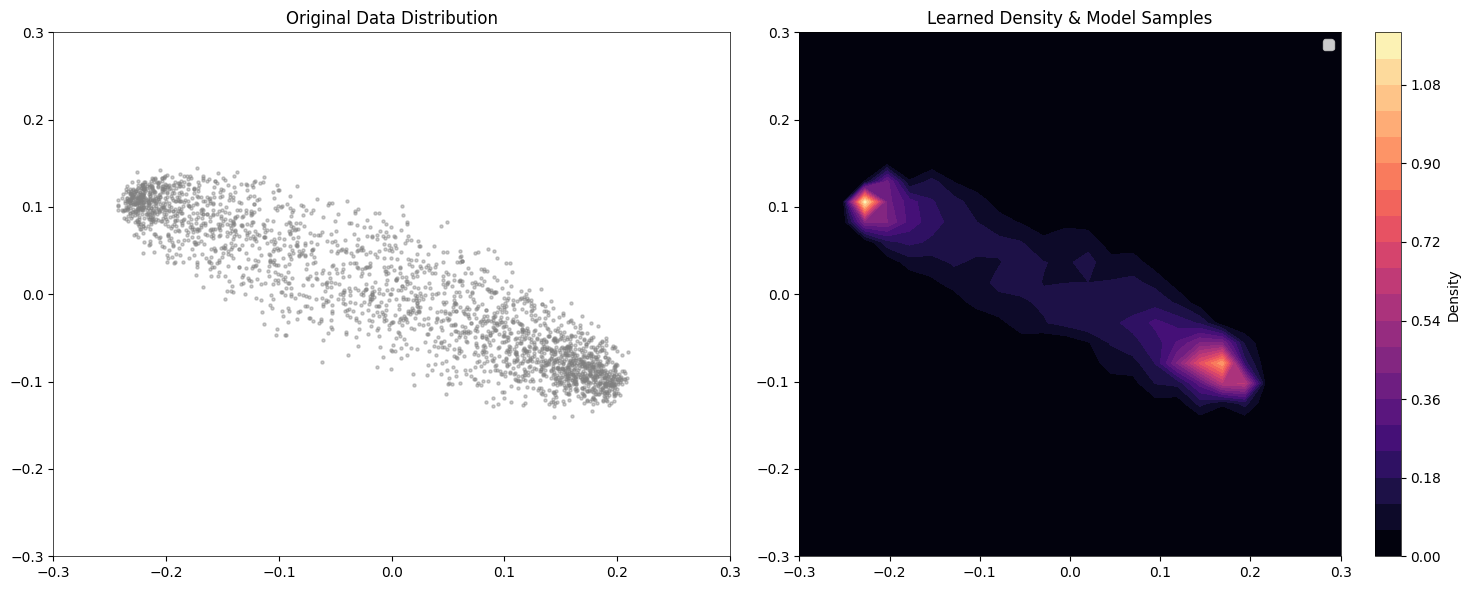

In [125]:
def plot_comparison(model, standardizer, raw_data, num_samples=20000):
    model.eval()

    # 1. Generate Samples from the model
    with torch.no_grad():
        # Sample from N(0,1) -> Transform through Flow -> Inverse Z-score
        z_samples = model.sample(num_samples)
        x_samples_scaled = z_samples
        x_samples_raw = standardizer.inverse_transform(x_samples_scaled).numpy()

    # 2. Create Density Grid for Contours
    x_min, x_max = raw_data[:, 0].min() - 1, raw_data[:, 0].max() + 1
    y_min, y_max = raw_data[:, 1].min() - 1, raw_data[:, 1].max() + 1
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 100), np.linspace(y_min, y_max, 100))
    grid_raw = torch.tensor(np.c_[xx.ravel(), yy.ravel()], dtype=torch.float32)

    with torch.no_grad():
        grid_scaled = standardizer.transform(grid_raw)
        probs = model.log_prob(grid_scaled).exp().reshape(xx.shape).numpy()

    # 3. Plotting
    fig, axes = plt.subplots(1, 2, figsize=(15, 6))

    # Left Plot: Original Data
    axes[0].scatter(raw_data[:, 0], raw_data[:, 1], s=5, color='gray', alpha=0.4)
    axes[0].set_title("Original Data Distribution")
    axes[0].set_xlim(-.3,.3)
    axes[0].set_ylim(-.3,.3)

    # Right Plot: Model Density + Generated Samples
    # Use a contourf to show the "landscape" the model learned
    cont = axes[1].contourf(xx, yy, probs, levels=20, cmap='magma')
    # Overlay actual samples generated by the model
    # axes[1].scatter(x_samples_raw[:, 0], x_samples_raw[:, 1], s=5,
    #                 color='cyan', alpha=0.5, label='Generated Samples')

    axes[1].set_title("Learned Density & Model Samples")
    axes[1].set_xlim(-.3,.3)
    axes[1].set_ylim(-.3,.3)
    axes[1].legend()

    plt.colorbar(cont, ax=axes[1], label='Density')
    plt.tight_layout()
    plt.show()

# Run the comparison
plot_comparison(model, standardizer, raw_X)

